# Cantilever cylinder under a follower pressure: Schweizerhof and Ramm (1984)

K. Schweizerhof and E. Ramm, *Displacement dependent pressure loads in nonlinear finite element analyses*, Computers & Structures 18 (1984) 1099-1114, Section 6.4, "Cylindrical cantilever shell under uniform pressure", Fig. 12 (p. 1110), Table 4 (p. 1111) and Fig. 13 (p. 1112).

Cylinders with $E = 2.1 \times 10^6$, $\mu = 0.3$, $R = 100$, the upper edge free and the lower edge hinged, $v = w = m_x = 0$, with the warping either completely restrained, B1, $u = 0$ along the edge, or partially restrained, B2, $u$ fixed at one point only, under a uniform external pressure

$$p = K \frac{E}{12(1 - \mu^2)} \left(\frac{t}{R}\right)^3 \qquad \text{Eq. (60)}$$

either constant directional (dead, $k_c$ in Table 4) or hydrostatic (follower, $k_f$). The free edge makes the follower load nonconservative: its load stiffness is unsymmetric. Shell 1, $L/R = 6$, $R/t = 100$, with an imperfection of 1 % of $t$ in the shape of the linear buckling mode is traced in Fig. 13 under the follower pressure, $K$ against the maximum displacement $w_i/t$.

This notebook reproduces Table 4 for the cantilevers and Fig. 13 with the Riks method of `structsolve`, with the count of the negative eigenvalues of the unsymmetric tangent stiffness matrix along the paths. The values of Fig. 13 were read on the page rendered at 300 dpi, with the axes located from the frame and the ticks, see `schweizerhof1984_utils.py`: precision about $\pm 0.05$ in $K$ and $\pm 0.01$ in $w/t$ ($\pm 0.02$ below $w/t = 0.1$, where the curve is nearly vertical). The model is that of the test `tests/tests_shell/test_schweizerhof1984_cantilever_postbuckling.py`. See also `schweizerhof1984_pressure_loads.ipynb` for Tables 2-4 of the paper, with the hinged cylinders and a load imperfection.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import schweizerhof1984_utils as su
from follower_utils import markdown_table

## panels model

As in the paper (Fig. 12), a sector of half a circumferential wave, $b = \pi R/n$, is modelled, with symmetry conditions on the straight edges, `schweizerhof_sector` of `tests/tests_shell/test_follower_pressure_validation.py`: one `Shell` of the model `cylshell_clpt_sanders`, the CLPT with the kinematics of Sanders. With $n = 3$ circumferential waves for shell 1 the shallow-shell approximation of Donnell is not accurate; Sanders' kinematics keep $v/r$ in the rotation $\phi_y = -w_{,y} + v/r$ and in the curvatures. The flags of Bardell's functions:

| Edge | Condition | Flags |
|---|---|---|
| $x = 0$, lower | B1: $u = v = w = 0$; B2: $v = w = 0$ | `x1u = x1v = x1w = 0` (B1), `x1v = x1w = 0` (B2) |
| $x = L$, upper | free | none |
| $y = 0$, $y = b$ | symmetry, $v = w_{,y} = 0$ | `y1v = y1wr = 0`, same for `y2` |

For B2 the axial rigid-body motion is fixed at $x = 0$, $y = b/2$, a node of $\cos(n y/R)$, with a penalty stiffness `calc_stiffness_point_constraint`. The pressure is `add_pressure_load(-p, cte=False, follower=True)`, negative inwards, with the pressure of $K = 1$, such that the load factor is $K$. Its load stiffness `calc_kCfollower` is unsymmetric: the linear buckling problem is `lb(kC0, kG + kCfollower)`, which `structsolve` solves with its solvers of unsymmetric matrices, $k_c$ being that of `lb(kC0, kG)`.

### Convergence of the discretization

$m$ terms along $x$, $n_t$ along $y$: shell 1, B1 and B2.

In [2]:
conv = {}
for bc in ('B1', 'B2'):
    for nt in (6, 8, 10):
        for m in (8, 10, 14, 18, 22):
            s, kP = su.build_shell(bc, m=m, nt=nt)
            conv[bc, nt, m] = (su.buckling_K(s, kP, follower=False)[0], su.buckling_K(s, kP)[0])
rows = []
for (bc, nt, m), (kc, kf) in conv.items():
    kc_ref, kf_ref = conv[bc, 10, 22]
    rows.append([bc, nt, m, '%.3f (%+.2f %%)' % (kc, 100*(kc/kc_ref - 1)), '%.3f (%+.2f %%)' % (kf, 100*(kf/kf_ref - 1))])
display(Markdown(markdown_table(['', '$n_t$', '$m$', '$k_c$ (vs. 22 x 10)', '$k_f$ (vs. 22 x 10)'], rows)))

|  | $n_t$ | $m$ | $k_c$ (vs. 22 x 10) | $k_f$ (vs. 22 x 10) |
|---|---|---|---|---|
| B1 | 6 | 8 | 10.996 (+1.18 %) | 9.790 (+1.19 %) |
| B1 | 6 | 10 | 10.987 (+1.11 %) | 9.783 (+1.12 %) |
| B1 | 6 | 14 | 10.966 (+0.91 %) | 9.763 (+0.92 %) |
| B1 | 6 | 18 | 10.957 (+0.83 %) | 9.755 (+0.83 %) |
| B1 | 6 | 22 | 10.956 (+0.82 %) | 9.755 (+0.83 %) |
| B1 | 8 | 8 | 10.906 (+0.36 %) | 9.710 (+0.36 %) |
| B1 | 8 | 10 | 10.898 (+0.29 %) | 9.702 (+0.29 %) |
| B1 | 8 | 14 | 10.876 (+0.09 %) | 9.683 (+0.09 %) |
| B1 | 8 | 18 | 10.868 (+0.01 %) | 9.675 (+0.01 %) |
| B1 | 8 | 22 | 10.867 (+0.00 %) | 9.675 (+0.00 %) |
| B1 | 10 | 8 | 10.906 (+0.36 %) | 9.710 (+0.36 %) |
| B1 | 10 | 10 | 10.898 (+0.29 %) | 9.702 (+0.29 %) |
| B1 | 10 | 14 | 10.876 (+0.09 %) | 9.683 (+0.09 %) |
| B1 | 10 | 18 | 10.867 (+0.01 %) | 9.675 (+0.01 %) |
| B1 | 10 | 22 | 10.867 (+0.00 %) | 9.675 (+0.00 %) |
| B2 | 6 | 8 | 9.206 (+1.30 %) | 8.193 (+1.30 %) |
| B2 | 6 | 10 | 9.202 (+1.26 %) | 8.190 (+1.27 %) |
| B2 | 6 | 14 | 9.186 (+1.08 %) | 8.175 (+1.09 %) |
| B2 | 6 | 18 | 9.179 (+1.00 %) | 8.169 (+1.01 %) |
| B2 | 6 | 22 | 9.179 (+1.00 %) | 8.169 (+1.01 %) |
| B2 | 8 | 8 | 9.115 (+0.30 %) | 8.111 (+0.30 %) |
| B2 | 8 | 10 | 9.111 (+0.26 %) | 8.108 (+0.26 %) |
| B2 | 8 | 14 | 9.095 (+0.08 %) | 8.094 (+0.08 %) |
| B2 | 8 | 18 | 9.088 (+0.00 %) | 8.088 (+0.00 %) |
| B2 | 8 | 22 | 9.088 (+0.00 %) | 8.087 (+0.00 %) |
| B2 | 10 | 8 | 9.115 (+0.30 %) | 8.111 (+0.30 %) |
| B2 | 10 | 10 | 9.111 (+0.26 %) | 8.108 (+0.26 %) |
| B2 | 10 | 14 | 9.095 (+0.08 %) | 8.094 (+0.08 %) |
| B2 | 10 | 18 | 9.088 (+0.00 %) | 8.088 (+0.00 %) |
| B2 | 10 | 22 | 9.088 (+0.00 %) | 8.087 (+0.00 %) |

$14 \times 8$ terms, the default of `schweizerhof_sector` and used below, are within 0.1 % of $22 \times 10$ terms for both $k_c$ and $k_f$; 6 terms along $y$ are 0.8 % to 1 % too stiff. The convergence is monotonic from above. The thinner shell 3 is checked in the next table with $22 \times 8$ terms.

## Table 4: linear buckling of the cantilevers

$k_f$ of the paper is that with the load stiffness symmetrized by Eq. (63), $\boldsymbol{K}_{L,sym}$; Eqs. (64) and (65) give 8.12 and 8.09 for shell 1, B2, 15.46 and 15.38 for shell 2 and 35.50 and 35.46 for shell 3. panels solves the unsymmetric problem. $n$ is that of the paper, adopted also for B2 (for which lower loads exist with one wave less, see `schweizerhof1984_pressure_loads.ipynb`).

In [3]:
rows = []
for (shell, LR, Rt, n), b1, b2 in su.TABLE4:
    for bc, (kc_ref, kf_ref) in (('B1', b1), ('B2', b2)):
        vals = []
        for m in (14, 22):
            s, kP = su.build_shell(bc, m=m, L=LR*su.R, t=su.R/Rt, n=n)
            vals.append((su.buckling_K(s, kP, follower=False)[0], su.buckling_K(s, kP)[0]))
        (kc, kf), (kc22, kf22) = vals
        cell = lambda k, k22, ref: '%.2f, %.2f' % (k, k22) + ('' if ref is None else ' (%+.1f %%)' % (100*(k22/ref - 1)))
        rows.append(['%d, L/R = %g, R/t = %g, n = %d' % (shell, LR, Rt, n) if bc == 'B1' else '', bc,
                     '%.2f' % kc_ref, cell(kc, kc22, kc_ref),
                     '-' if kf_ref is None else '%.2f' % kf_ref, cell(kf, kf22, kf_ref),
                     '%.1f / %.1f' % (100*(kc_ref - kf_ref)/kf_ref, 100*(kc22 - kf22)/kf22) if kf_ref else '- / %.1f' % (100*(kc22 - kf22)/kf22)])
display(Markdown(markdown_table(['shell', '', '$k_c$ paper', '$k_c$ panels, 14 x 8, 22 x 8', '$k_f$ paper, Eq. (63)',
                                 '$k_f$ panels, 14 x 8, 22 x 8', '$(k_c - k_f)/k_f$ %, paper / panels'], rows)))

| shell |  | $k_c$ paper | $k_c$ panels, 14 x 8, 22 x 8 | $k_f$ paper, Eq. (63) | $k_f$ panels, 14 x 8, 22 x 8 | $(k_c - k_f)/k_f$ %, paper / panels |
|---|---|---|---|---|---|---|
| 1, L/R = 6, R/t = 100, n = 3 | B1 | 10.89 | 10.88, 10.87 (-0.2 %) | 9.70 | 9.68, 9.67 (-0.3 %) | 12.3 / 12.3 |
|  | B2 | 9.11 | 9.10, 9.09 (-0.2 %) | 8.10 | 8.09, 8.09 (-0.2 %) | 12.5 / 12.4 |
| 2, L/R = 3, R/t = 100, n = 4 | B1 | 20.85 | 20.77, 20.77 (-0.4 %) | 19.58 | 19.51, 19.51 (-0.4 %) | 6.5 / 6.5 |
|  | B2 | 16.43 | 16.37, 16.37 (-0.4 %) | 15.42 | 15.37, 15.37 (-0.3 %) | 6.5 / 6.5 |
| 3, L/R = 3, R/t = 500, n = 6 | B1 | 45.83 | 45.67, 45.62 (-0.5 %) | - | 44.42, 44.37 | - / 2.8 |
|  | B2 | 36.48 | 36.40, 36.36 (-0.3 %) | 35.48 | 35.40, 35.36 (-0.3 %) | 2.8 / 2.8 |

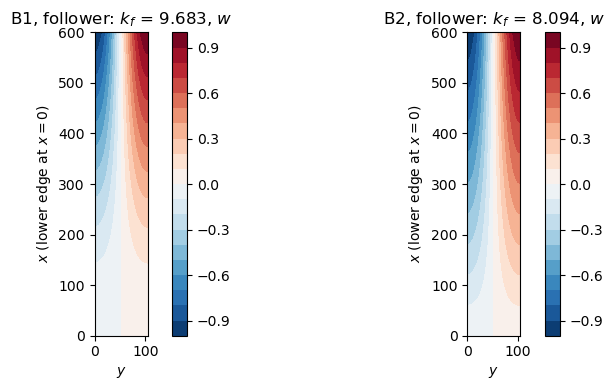

In [4]:
s1, kP1 = su.build_shell('B1')
K_f1, mode1 = su.buckling_K(s1, kP1)
s2, kP2 = su.build_shell('B2')
K_f2, mode2 = su.buckling_K(s2, kP2)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, s, mode, bc, K in ((axes[0], s1, mode1, 'B1', K_f1), (axes[1], s2, mode2, 'B2', K_f2)):
    s.uvw(mode, gridx=60, gridy=30)
    w = s.fields['w']/np.abs(s.fields['w']).max()
    cf = ax.contourf(s.plot_mesh['Ys'], s.plot_mesh['Xs'], w, levels=21, cmap='RdBu_r')
    ax.set_aspect('equal'); ax.set_xlabel('$y$'); ax.set_ylabel('$x$ (lower edge at $x = 0$)')
    ax.set_title('%s, follower: $k_f$ = %.3f, $w$' % (bc, K))
    plt.colorbar(cf, ax=ax)
plt.tight_layout()

## The initial imperfection

Neither `panels` nor `structsolve` takes a geometric imperfection. It is added exactly as in `simo1990_cylinder_postbuckling.ipynb`, here for the kinematics of Sanders, whose non-linear strains $\frac{1}{2}\phi_x^2$, $\frac{1}{2}\phi_y^2$, $\phi_x \phi_y$ are quadratic forms of the rotations $\phi_x = -w_{,x}$, $\phi_y = -w_{,y} + v/r$, linear in $\boldsymbol{c}$. With the Ritz vector $\boldsymbol{c}_0$ of the imperfection $w_0$ (the $w$ part of the mode of the follower load, $u = v = 0$, scaled to $\max|w_0| = 0.01 t$), the strains of the imperfect shell are $\boldsymbol{\varepsilon}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{\varepsilon}(\boldsymbol{c}_0)$, whence

$$\boldsymbol{F}_{int,imp}(\boldsymbol{c}) = \boldsymbol{F}_{int}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{F}_{int}(\boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0) \boldsymbol{c} \qquad \boldsymbol{K}_{T,imp}(\boldsymbol{c}) = \boldsymbol{K}_T(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{K}_G(\boldsymbol{N}_0)$$

with $\boldsymbol{K}_G(\boldsymbol{N}_0)$ the geometric stiffness of the resultants of $\boldsymbol{c}_0$, linear and non-linear parts, integrated at the Gauss points with the rows of $\phi_x$ and $\phi_y$ (`calc_kG_N` of the test; `Shell.calc_kG(c=c0)` has the linear resultants only). The follower pressure acts on the imperfect geometry: its force vector at $\boldsymbol{c}$ is $\boldsymbol{F}_p(\boldsymbol{c} + \boldsymbol{c}_0)$, `calc_fext(c=c + c0)`, the reference vector of the load factor being $\boldsymbol{F}_p(\boldsymbol{c}_0)$, and $\boldsymbol{F}_{int,imp}$ contains $-K(\boldsymbol{F}_p(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{F}_p(\boldsymbol{c}_0))$ at the load factor $K$, `ImperfectShell` of the test. The checks below, with an imperfection of 50 % of $t$ for B2: the unstressed imperfect shell, the tangent against central differences, unsymmetric with the skew part of the load stiffness, and the elastic internal forces against the gradient of the strain energy of $\boldsymbol{\varepsilon}(\boldsymbol{c} + \boldsymbol{c}_0) - \boldsymbol{\varepsilon}(\boldsymbol{c}_0)$, run by `test_imperfection_identities`:

In [5]:
import test_schweizerhof1984_cantilever_postbuckling as tst
tst.test_imperfection_identities()
print('identities verified')

identities verified


## Riks analyses of the imperfect shell 1

`NL_method = 'arc_length_riks'`, `final_load_factor = None`, `initialInc = 1`, `maxInc = 4`, the stop criterion `value_reached` of $\max|w|/t = 3$ ($w$ the displacement, without the imperfection), `inertia = True` and `inertia_num_eigvals = 6`, the other attributes of `Analysis` at their defaults. The tangent stiffness matrix is unsymmetric, so the inertia is not the count of PARDISO but the number of negative real eigenvalues among the 6 of smallest magnitude, by ARPACK on the LU factorization of SuperLU, with the sign of its determinant. B1, the boundary conditions stated by the paper for Fig. 13, and B2.

In [6]:
res = {}
for bc in ('B1', 'B2'):
    res[bc] = r = su.riks(bc, 0.01, 3., inc=1., max_inc=4.)
    print('%s: %2d increments, %5.1f s, max. relative residual %.1e, k_f = %.3f, K at w/t = 3: %.3f, '
          'negative eigenvalues %s, determinant signs %s'
          % (bc, len(r['K']), r['time'], r['max_residual'], r['K_f'], np.interp(3., r['w'], r['K']),
             sorted(set(r['nneg'])), sorted(set(r['det']))))

B1: 24 increments,  94.4 s, max. relative residual 7.5e-09, k_f = 9.683, K at w/t = 3: 9.643, negative eigenvalues [0], determinant signs [1]


B2: 21 increments,  84.2 s, max. relative residual 3.9e-09, k_f = 8.094, K at w/t = 3: 8.072, negative eigenvalues [0], determinant signs [1]


## Comparison with Fig. 13

| $w/t$ | $K$, Fig. 13 | $K$, panels, B1 | $K$, panels, B2 |
|---|---|---|---|
| 0.017 | 5.10 | 4.95 (-2.9 %) | 4.45 (-12.7 %) |
| 0.022 | 5.56 | 5.55 (-0.2 %) | 4.66 (-16.2 %) |
| 0.039 | 6.02 | 7.31 (+21.4 %) | 5.37 (-10.8 %) |
| 0.049 | 6.48 | 7.59 (+17.2 %) | 5.78 (-10.7 %) |
| 0.073 | 6.93 | 8.28 (+19.4 %) | 6.78 (-2.1 %) |
| 0.138 | 7.39 | 8.88 (+20.1 %) | 7.31 (-1.1 %) |
| 0.174 | 7.52 | 9.10 (+21.0 %) | 7.42 (-1.3 %) |
| 0.211 | 7.62 | 9.21 (+20.8 %) | 7.53 (-1.2 %) |
| 0.286 | 7.72 | 9.34 (+21.0 %) | 7.75 (+0.5 %) |
| 0.398 | 7.78 | 9.43 (+21.3 %) | 7.88 (+1.3 %) |
| 0.510 | 7.82 | 9.49 (+21.3 %) | 7.93 (+1.4 %) |
| 0.696 | 7.88 | 9.54 (+21.1 %) | 7.97 (+1.2 %) |
| 0.883 | 7.91 | 9.57 (+21.0 %) | 8.00 (+1.1 %) |
| 1.069 | 7.92 | 9.59 (+21.1 %) | 8.02 (+1.2 %) |
| 1.443 | 7.93 | 9.61 (+21.2 %) | 8.04 (+1.4 %) |
| 2.003 | 7.96 | 9.63 (+21.0 %) | 8.06 (+1.2 %) |
| 2.563 | 7.99 | 9.64 (+20.6 %) | 8.07 (+0.9 %) |
| 2.936 | 7.99 | 9.64 (+20.7 %) | 8.07 (+1.0 %) |
| perfect shell | 8.04 | 9.68 ($k_f$) | 8.09 ($k_f$) |

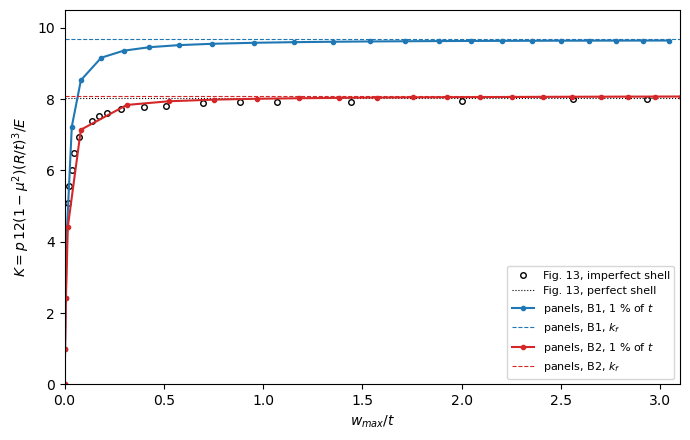

In [7]:
fig13 = np.array(su.FIG13_IMPERFECT)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(fig13[:, 0], fig13[:, 1], 'o', ms=4, mfc='none', color='k', label='Fig. 13, imperfect shell')
ax.axhline(su.FIG13_PERFECT_K, color='k', lw=0.8, ls=':', label='Fig. 13, perfect shell')
for bc, color in (('B1', 'C0'), ('B2', 'C3')):
    r = res[bc]
    ax.plot([0] + r['w'], [0] + r['K'], '.-', color=color, label='panels, %s, 1 %% of $t$' % bc)
    ax.axhline(r['K_f'], color=color, ls='--', lw=0.8, label='panels, %s, $k_f$' % bc)
ax.set_xlim(0, 3.1); ax.set_ylim(0, 10.5)
ax.set_xlabel('$w_{max}/t$'); ax.set_ylabel('$K = p\\,12(1 - \\mu^2)(R/t)^3/E$')
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout()

rows = []
for w, K in su.FIG13_IMPERFECT:
    k1, k2 = (np.interp(w, res[bc]['w'], res[bc]['K']) for bc in ('B1', 'B2'))
    rows.append(['%.3f' % w, '%.2f' % K, '%.2f (%+.1f %%)' % (k1, 100*(k1/K - 1)), '%.2f (%+.1f %%)' % (k2, 100*(k2/K - 1))])
rows.append(['perfect shell', '%.2f' % su.FIG13_PERFECT_K, '%.2f ($k_f$)' % res['B1']['K_f'], '%.2f ($k_f$)' % res['B2']['K_f']])
display(Markdown(markdown_table(['$w/t$', '$K$, Fig. 13', '$K$, panels, B1', '$K$, panels, B2'], rows)))

The first points, below $w/t = 0.05$, lie on the nearly vertical part of the curve, where the reading of $w/t$ is uncertain by $\pm 0.02$, i.e. by a large fraction of $w/t$ itself.

## Inertia of the unsymmetric tangent stiffness matrix

Along both imperfect paths the count is zero and the determinant positive: the load increases monotonically towards $k_f$, without a limit point, and the tangent stiffness matrix keeps positive real eigenvalues, the plateau of Fig. 13 being approached from below. A negative eigenvalue appears on the fundamental path of the perfect shell beyond its bifurcation: B1, Riks with `initialInc = maxInc = 1` up to $K = 11$, the count among the 6 (default above) and the 20 eigenvalues of smallest magnitude, by ARPACK on the LU factorization. `structsolve` counts the eigenvalues of $\boldsymbol{S} \boldsymbol{K}_T \boldsymbol{S}$, $\boldsymbol{S} = |\mathrm{diag}(\boldsymbol{K}_0)|^{-1/2}$ of the linear stiffness matrix, fixed along the path: in the unknowns of the shell, the negative eigenvalue of $\boldsymbol{K}_T$ itself is far from the smallest ones by magnitude, the Ritz terms of smallest norm (high-order functions of Bardell) having many eigenvalues closer to zero than the soft physical mode, see the next cell.

In [8]:
perf = {k: su.riks('B1', 0., 11., inc=1., num_eigvals=k) for k in (6, 20)}
r0 = perf[6]
rows = []
for i, K in enumerate(r0['K']):
    rows.append(['%.2f' % K, '%+d' % r0['det'][i]] + [str(perf[k]['nneg'][i]) for k in perf])
display(Markdown(markdown_table(['$K$', 'sign of det', 'count, 6', 'count, 20'], rows)))
bif = {bc: su.bifurcation_load(bc) for bc in ('B1', 'B2')}
for bc, (Kb, Kf) in bif.items():
    print('%s: bifurcation of the fundamental path, by the sign of the determinant, at K = %.3f; linear k_f = %.3f'
          % (bc, Kb, Kf))

| $K$ | sign of det | count, 6 | count, 20 |
|---|---|---|---|
| 1.00 | +1 | 0 | 0 |
| 2.00 | +1 | 0 | 0 |
| 3.00 | +1 | 0 | 0 |
| 4.00 | +1 | 0 | 0 |
| 5.00 | +1 | 0 | 0 |
| 6.00 | +1 | 0 | 0 |
| 7.00 | +1 | 0 | 0 |
| 8.00 | +1 | 0 | 0 |
| 9.00 | +1 | 0 | 0 |
| 10.00 | -1 | 0 | 1 |
| 11.00 | -1 | 0 | 1 |

B1: bifurcation of the fundamental path, by the sign of the determinant, at K = 9.685; linear k_f = 9.683
B2: bifurcation of the fundamental path, by the sign of the determinant, at K = 8.095; linear k_f = 8.094


In [9]:
s, kP = su.build_shell('B1')
sm = su.ImperfectShell(s, np.zeros(s.get_size()), kP)
from structsolve import solve
c = solve(sm.calc_kC(), 10.*sm.calc_fext(), silent=True)
kT = sm.calc_kT(c, inc=10.).toarray()
nz = np.flatnonzero(np.abs(kT).sum(axis=1) > 0)
A = kT[np.ix_(nz, nz)]
d = 1/np.sqrt(np.abs(sm.calc_kC().diagonal()[nz]))
for label, M in (('K_T', A), ('S K_T S', d[:, None]*A*d[None, :])):
    ev = np.linalg.eigvals(M)
    order = np.argsort(np.abs(ev))
    ineg = np.flatnonzero(ev.real < 0)
    print('%s: the negative eigenvalue at K = 10 (linear prestate) is number %s of %d by magnitude'
          % (label, [int(np.flatnonzero(order == i)[0]) + 1 for i in ineg], len(ev)))

K_T: the negative eigenvalue at K = 10 (linear prestate) is number [142] of 260 by magnitude
S K_T S: the negative eigenvalue at K = 10 (linear prestate) is number [9] of 260 by magnitude


## Discussion

- **Table 4.** With $22 \times 8$ terms, $k_c$ and $k_f$ of the cantilevers are 0.2 % to 0.5 % below the values of the paper, whose 24 bicubic elements (3 x 8) the authors judged converged; the unsymmetric eigenvalue problem gives the $k_f$ of the three symmetrizations of the paper, which differ by 0.4 % at most, and the follower load lowers the critical pressure by 12.3 % (B1) and 12.4 % (B2) for shell 1, as in the paper (12.3 % and 12.5 %), and by 6.5 % and 2.8 % for shells 2 and 3, as in the paper. B1 is 16 % to 21 % above B2, as in the paper.
- **Fig. 13 is the curve of B2.** The imperfect B1 path of panels approaches its $k_f = 9.68$ from below and reaches $K = 9.64$ at $w/t = 3$, 20 % above the curve of Fig. 13, whose perfect shell is at $K = 8.04$, the $k_f$ of B2 in Table 4 (8.09 to 8.12), not that of B1 (9.70). The B2 path of panels follows the figure within 1.5 %: 1 % to 2 % below it from $w/t = 0.07$ to 0.21 (the knee, $K \approx 7$ at $w/t \approx 0.08$) and 0.5 % to 1.4 % above it, 0.04 to 0.11 in $K$, from $w/t = 0.29$ to 3, about the difference of the perfect shells, $k_f$ = 8.09 against 8.04 read; below $w/t = 0.05$ the differences, up to 16 %, are within the reading precision of $w/t$ on the nearly vertical part of the curve. The text of the paper states B1 for Fig. 13; the plateau and the perfect shell of the figure are those of B2, or of a B1 analysis with a load or support of B2. The comparison with the paper is therefore made with B2, and B1 is the analysis stated in the text.
- **No limit point.** Under the follower pressure the imperfect cantilever has a stable, slightly rising post-buckling path up to $w/t = 3$: the load approaches the bifurcation load asymptotically, $k_f - K = 0.04$ (B1) and $0.02$ (B2) at $w/t = 3$, as the current stiffness parameter of the figure, which falls to zero at the plateau. The nonlinear bifurcation of the fundamental path, by the sign of the determinant, coincides with the linear $k_f$ to 0.02 %: the prebuckling state is nearly linear.
- **Inertia counts.** Along the imperfect paths both the count and the sign of the determinant say that the tangent stiffness matrix has no negative eigenvalue. Beyond the bifurcation of the perfect shell the determinant changes sign at the first increment past $k_f$, and the count of `inertia_num_eigvals` = 20 finds the one negative eigenvalue there; 6 eigenvalues are too few, the negative one being the 9th by magnitude of $\boldsymbol{S} \boldsymbol{K}_T \boldsymbol{S}$ (previous cell), and `structsolve` then warns (silenced here) that the parity of the count differs from the sign of the determinant. The count relies on the scaling of `structsolve` by $\mathrm{diag}(\boldsymbol{K}_0)$: among the eigenvalues of $\boldsymbol{K}_T$ itself, in the unknowns of the shell, the negative one is far down by magnitude (previous cell) and a count of the smallest ones would miss it, while the sign of the determinant alone sees the bifurcation in any case.